# Agent Performance Evaluation (PART-A)
#### Some questions to be addressed in this notebook..

1. Verification of learning: Does learning beat random and scripted agents?
     Furthermore, does this hold in both v3 and v4 worlds?

2. Ablation: Which inputs help or hurt the DQN (move-only / + knowledge / + threat grid / + roads)?
    How can I measure these impacts?

3. AUC: Does the reasoning-bank in v5 learn faster than the plain move-only DQN in v4? 
    (v4 and v5 are the same simulation mechanics with different agent being tested)

4. Mechanisms for failure: When and how do agents get caught? 
    Does this differ across agents and worlds, if true, how so?
    How do these differences, if any, impact or inform the analysis?

5. Tuning: Based on the complete analysis, what can be done to yield additional insights?
    Are there any changes that can be made to improve agent learning speed, accuracy, or overall performance?

#### But first, lets talk about simulation versions **V3,V4,V5**

I'm using these 3 experiments for an initial analysis as they demonstrate differences in agent performance under different simulation mechanics, while again, also being complete enough for the first agent comparisons to be made, building intuition regarding driving factors for speed, accuracy, and performance.

V3...
- was the earliest of experiments with simpler world mechanics
- had poacher trips run with certainty once every day at midnight (default setting "start_hour = 0")
- produced absolute poacher capture conditions whenever a poacher came within the ranger station's detection radius
- set identical ranges of detection regardless of night/day condition. In theory, riding a motorbike at night with headlights on would draw more attention, be easier to spot.
- training arms were "dqn_full", "dqn_full_road", "dqn_knowledge", "dqn_move_only", "dqn_move_road", and the two initial reasoning bank agents "rb_every_trip", "rb_outcomes"
- ran training for these 7 agent arms, each with 5 seeds running for 1000 days (max of 1000 trips).
- tested a total of 9 agent arms, or 45 runs (includes additional 2 non-learning agents) for for 200 days each (max 200 trips each).

V4...
- has slightly improved world mechanics matching v5
- enabled trips to start at random times of the day
- reduces capture probability of poacher within ranger station's detection radius to 10% per minute within range
- changes the event describing the above capture condition to “Spotted from the station (off duty)” from a general “Visual detection” event
- sets heighted detection range at night to 1.5 x visibility score
- traing arms were "dqn_full", "dqn_full_road", "dqn_knowledge", "dqn_move_only", "dqn_move_road"
- ran training for these 5 agent arms, each again with 5 seeds running for 1000 days.
- tested a total of 7 agent arms, or 35 runs, again for 200 days.

V5...
- experienced the same simulation world as v4
- ran as an experiment assessing refactored reasoning bank agent performance after changes were made:
1. Rb2 lessons directly penalize moves made by setting score − 2.0 × average(weight × hit), removing the additional network inputs of rb1
2. Rb2 adds context to debrief regarding who caught them, not just where they were caught
3. Rb2 encourages exploration during early learning stages of training, slowly increasing the weight of move penalties from LLM lessons until exploration has reached a floor
- training arms were "rb2_every_trip", "rb2_outcomes"
- ran training for these 2 agent arms, each with 5 seeds running for 1000 days.
- tested two agent arms, or 10 runs, for 200 days each.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split

In [2]:
# Store csv as df and read columns for reference
df = pd.read_csv(r"trips_all.csv")
df.columns

Index(['experiment', 'description', 'world', 'arm', 'seed', 'bonus_strength',
       'phase', 'trip', 'party', 'entry', 'target', 'start_tick', 'end_tick',
       'hours', 'outcome', 'end_reason', 'leopard_found', 'closest_approach_m',
       'poacher_success', 'ranger_failed', 'reward', 'epsilon', 'trip_index',
       'caught', 'timed_out', 'start_hour', 'mean_loss', 'mean_q',
       'lessons_active', 'w_avoid_villages', 'w_avoid_station_area',
       'w_avoid_high_centrality', 'w_prefer_low_viewshed',
       'w_avoid_capture_sites', 'w_avoid_threat_cells'],
      dtype='object')

In [3]:
# Isolating v5,v4, and v3 experiments, simplifying naming
VERSIONS = {"ablation_v3": "v3", "ablation_v4_realistic": "v4", "ablation_v5_rb2": "v5"}
# Create a new df
df = df[df["experiment"].isin(VERSIONS)].copy()
df["version"] = df["experiment"].map(VERSIONS)

In [4]:
# Further separation with train test split for future analysis
train = df[df["phase"] == "train"]
eval_ = df[df["phase"] == "eval"]
# Drop empty columns
train = train.dropna(axis = 1, how = "all")
eval_ = eval_.dropna(axis = 1, how = "all")

In [5]:
# Total rows after scoping
print(f"Total rows after scope = {len(df)}. Expecting 62,872")

# Count trips by version and phase
df.groupby(["version", "phase"]).size().unstack()

# Expected...
#   version	  eval	 train
#     v3	 6,589	28,883
#     v4	 4,310	16,146
#     v5	   977	 5,967

Total rows after scope = 62872. Expecting 62,872


phase,eval,train
version,,
v3,6589,28883
v4,4310,16146
v5,977,5967


In [6]:
# Trip number for every agent arm under each simulation version and phase
df.groupby(["version", "phase", "arm"]).size().unstack()

arm            dqn_full  dqn_full_road  dqn_knowledge  dqn_move_only  \
version phase                                                          
v3      eval      578.0          613.0          682.0          747.0   
        train    3912.0         3856.0         4181.0         4226.0   
v4      eval      505.0          508.0          490.0          659.0   
        train    3078.0         3152.0         3242.0         3369.0   
v5      eval        NaN            NaN            NaN            NaN   
        train       NaN            NaN            NaN            NaN   

arm            dqn_move_road  rb2_every_trip  rb2_outcomes  rb_every_trip  \
version phase                                                               
v3      eval           790.0             NaN           NaN          631.0   
        train         4380.0             NaN           NaN         4200.0   
v4      eval           599.0             NaN           NaN            NaN   
        train         3305.0             NaN           NaN            NaN   
v5      eval             NaN           481.0         496.0            NaN   
        train            NaN          3020.0        2947.0            NaN   

arm            rb_outcomes  shortest_path  wanderer  
version phase                                        
v3      eval         615.0         1000.0     933.0  
        train       4128.0            NaN       NaN  
v4      eval           NaN          824.0     725.0  
        train          NaN            NaN       NaN  
v5      eval           NaN            NaN       NaN  
        train          NaN            NaN       NaN

Off the bat you can see some odd training behavior if you don't understand the changes which were made to the sim between v3-5.

The easiest to spot is shortest_path training trip counts dropping from the max of 1000 trips to 824 between v3 and v4.
In fact, every agent experiences some reduction in trip occurance between v3 and v4.

Let's look at how many unique "start_hour"s there are in v3 and v4 below..

In [7]:
df.groupby(["arm", "version"])["start_hour"].nunique().unstack()

version,v3,v4,v5
arm,,,
dqn_full,1.0,24.0,NaN
dqn_full_road,1.0,24.0,NaN
dqn_knowledge,1.0,24.0,NaN
dqn_move_only,1.0,24.0,NaN
dqn_move_road,1.0,24.0,NaN
rb2_every_trip,NaN,NaN,24.0
rb2_outcomes,NaN,NaN,24.0
rb_every_trip,1.0,NaN,NaN
rb_outcomes,1.0,NaN,NaN


As you can see, unique trip start times in v3 is only 1 because the trip start was set to default hour 0, or midnight every day. If this is the case, why aren't any other agents reaching the max trip number? That's because if you look at trip lengths, depending on the agent they can take hours to days to complete. In V3, if a trip is active and extends into a new day, a the new trip set at midnight will not fire.

With this said, v4 patches the default trip start hour, allowing trips to trigger at any point of the day. This is a bit more realistic, but this means since new trips can't fire if a trip is active, there will likely be more downtime between trips. Now, v4 shows 24 uniue "start_hour"s, verifying this change. To answer the original question, the shortest_path is the fastest of the agents averaging 4.7 hour trips so they never extended into another day in v3. With the updated world, this is now possible, and trip reduction is expected.

(4.7 hours) / 24 hours = ~20% chance of trip overlap between days

In [8]:
# Seeds per arm and version
df.groupby(["arm", "version"])["seed"].nunique().unstack()

version,v3,v4,v5
arm,,,
dqn_full,5.0,5.0,NaN
dqn_full_road,5.0,5.0,NaN
dqn_knowledge,5.0,5.0,NaN
dqn_move_only,5.0,5.0,NaN
dqn_move_road,5.0,5.0,NaN
rb2_every_trip,NaN,NaN,5.0
rb2_outcomes,NaN,NaN,5.0
rb_every_trip,5.0,NaN,NaN
rb_outcomes,5.0,NaN,NaN


Eval Table
- While training trips show how fast an agent learns, ideally accounting for noise and environmental factors, test trips show agent performance after training as a final evaluation.

- The eval table logs data for every run (every seed run for every arm) to assist with evaluating integrity of an agent's performance, given that we can derive insights from observed independent variation in performance for an agent trained independently with several different seeds.

In [9]:

# Eval Table
# One row per run(version × arm × seed) for every run 
runs = (
    eval_
    .groupby(["version", "arm", "seed"])
    .agg(
        trips=("trip", "size"),
        success=('poacher_success', 'mean'),
        caught=('caught', 'mean'),
        timed_out=('timed_out', 'mean'),
        hours=('hours', 'mean'),
    )
    .reset_index() # turns the group keys back into ordinary columns
)
len(runs)

90

In [10]:
# Reading into move_only arm performance across seeds
runs[(runs["version"] == "v4") & (runs["arm"] == "dqn_move_only")]

,version,arm,seed,trips,success,caught,timed_out,hours
60,v4,dqn_move_only,1,134,0.305970,0.298507,0.082090,11.675373
61,v4,dqn_move_only,2,121,0.322314,0.272727,0.074380,15.090909
62,v4,dqn_move_only,3,133,0.345865,0.203008,0.045113,11.775188
63,v4,dqn_move_only,4,131,0.274809,0.427481,0.076336,12.486260
64,v4,dqn_move_only,5,140,0.264286,0.307143,0.021429,9.055000


In [11]:
# Computing mean and std of successful trips for every arm in each version
# Averaging the average of seed performances and std
runs.groupby(['version', 'arm']).success.agg(["mean", "std"])

mean       std
version arm                               
v3      dqn_full        0.085616  0.026205
        dqn_full_road   0.091017  0.022818
        dqn_knowledge   0.242543  0.111014
        dqn_move_only   0.279284  0.076647
        dqn_move_road   0.309116  0.057563
        rb_every_trip   0.209633  0.027199
        rb_outcomes     0.196298  0.067024
        shortest_path   0.352000  0.024648
        wanderer        0.070500  0.018741
v4      dqn_full        0.098817  0.040065
        dqn_full_road   0.118960  0.030808
        dqn_knowledge   0.173999  0.095039
        dqn_move_only   0.302649  0.033586
        dqn_move_road   0.274630  0.046395
        shortest_path   0.357123  0.029329
        wanderer        0.070222  0.015971
v5      rb2_every_trip  0.260383  0.071678
        rb2_outcomes    0.256591  0.046373

In [12]:
#Reconciled against sim summary calculations
check = pd.read_csv(r"runs_all.csv")
check["version"] = check["experiment"].map(VERSIONS)
merged = runs.merge(check, on=["version", "arm", "seed"])
print(len(merged), (merged["success"].round(3) - merged["poacher_success_rate"]).abs().max())

90 0.0


In [13]:
# Training success rates, smoothing with average of previous trip samples
# Rolling results across 50-trip samples
curves = train[train["trip_index"] <= 500].sort_values("trip_index").copy()

curves["rolling_success"] = (
    curves.groupby(["version", "arm", "seed"])["poacher_success"].transform(lambda s: s.astype(float).rolling(50).mean())
)
curves.columns

Index(['experiment', 'description', 'world', 'arm', 'seed', 'bonus_strength',
       'phase', 'trip', 'party', 'entry', 'target', 'start_tick', 'end_tick',
       'hours', 'outcome', 'end_reason', 'leopard_found', 'closest_approach_m',
       'poacher_success', 'ranger_failed', 'reward', 'epsilon', 'trip_index',
       'caught', 'timed_out', 'start_hour', 'mean_loss', 'mean_q',
       'lessons_active', 'w_avoid_villages', 'w_avoid_station_area',
       'w_avoid_high_centrality', 'w_prefer_low_viewshed',
       'w_avoid_capture_sites', 'w_avoid_threat_cells', 'version',
       'rolling_success'],
      dtype='object')

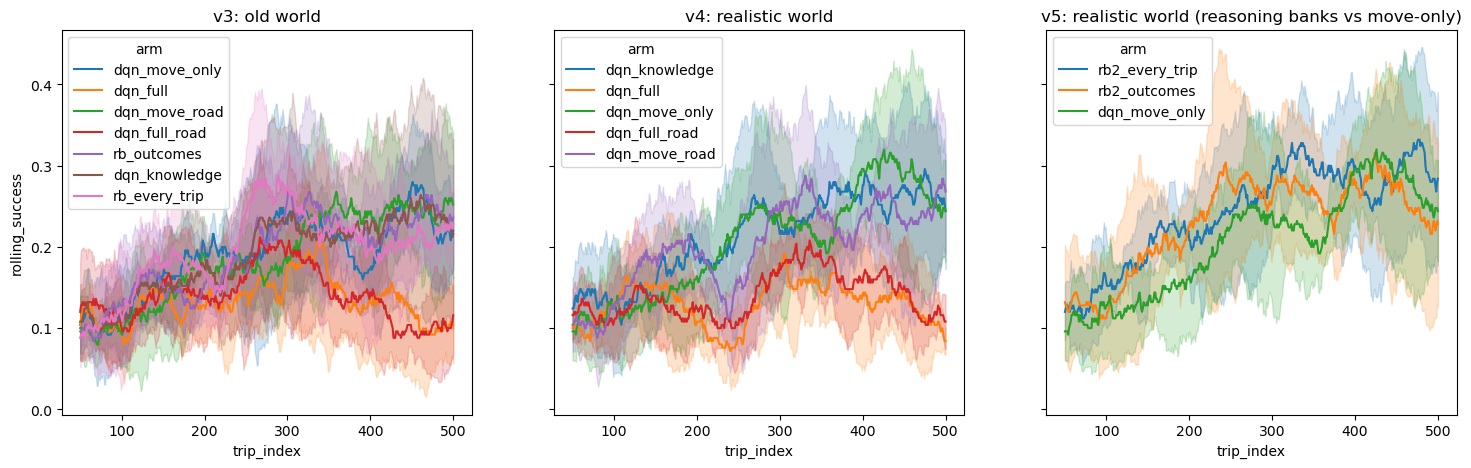

In [14]:
# Plots poacher rolling success rates from each agent arm across ~500 initial simulation training runs
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Panel A: v3 ablation (old world), all DQN arms
v3_panel = curves[(curves['version'] == 'v3')]
# Panel B: v4 ablation (realistic world), all DQN arms
v4_panel = curves[(curves['version'] == 'v4')]
# Panel C: Q3 — v5 rb2 arms PLUS v4 dqn_move_only as the baseline (same world, same base code)
v5_panel = curves[(curves["version"] == "v5") | ((curves["version"] == "v4") & (curves["arm"] == "dqn_move_only"))]


for ax, data, title in [(axes[0], v3_panel, "v3: old world"),
                        (axes[1], v4_panel, "v4: realistic world"),
                        (axes[2], v5_panel, "v5: realistic world (reasoning banks vs move-only)")]:
    sns.lineplot(data=data, x="trip_index", y="rolling_success", hue="arm", errorbar="sd", ax=ax)
    ax.set_title(title)

In [15]:
# Store average rates of success in first 500 training trips as auc (area under the curve)
auc = (train[train["trip_index"] <= 500]
       .groupby(["version", "arm", "seed"])["poacher_success"]
       .mean()
       .rename("auc")
       .reset_index())

auc

,version,arm,seed,auc
0,v3,dqn_full,1,0.148
1,v3,dqn_full,2,0.136
2,v3,dqn_full,3,0.148
3,v3,dqn_full,4,0.122
4,v3,dqn_full,5,0.098
...,...,...,...,...
65,v5,rb2_outcomes,1,0.280
66,v5,rb2_outcomes,2,0.268
67,v5,rb2_outcomes,3,0.236
68,v5,rb2_outcomes,4,0.164


Performance predictions for RB2..

* Based on the plots above I can see the rb has early successes with learning but stalls after about 300 training rounds.
* For these reasons I'd expect early AUC performance to be high for the RB, slowing down by late performance either matching or narrowly competing with the dqn. Regarding AUC, the RB seems to visually clear the dqn from the graph. Keep in mind this is not a final observation, since we haven't yet accounted for spread, noise, and std.

In [18]:
# Early performance / late performance / AUC for RB2

# Return trip_index window performance metrics for requested hi/lo
def window_mean(lo, hi, name):
    return (train[train["trip_index"].between(lo, hi)]
            .groupby(["version", "arm", "seed"])["poacher_success"].mean().rename(name))

table = pd.concat([window_mean(1, 100, "early"),
                   window_mean(401, 500, "late"),
                   window_mean(1, 500, "auc")], axis=1).reset_index()

compare = (table["version"] == "v5") | ((table["version"] == "v4") & (table["arm"] == "dqn_move_only"))
table[compare].groupby(["version", "arm"])[["early", "late", "auc"]].agg(["mean", "std"]).round(3)

early          late           auc       
                         mean    std   mean    std   mean    std
version arm                                                     
v4      dqn_move_only   0.112  0.042  0.264  0.080  0.201  0.029
v5      rb2_every_trip  0.138  0.039  0.284  0.097  0.238  0.027
        rb2_outcomes    0.122  0.062  0.252  0.105  0.226  0.052

The chart backs the claim that there may exist some early performance advantages for the RB over the DQN, but late success rates with current standard deviation show no clear winner. 

Let's look at p-values...

In [ ]:
baseline = table[(table["version"] == "v4") & (table["arm"] == "dqn_move_only")]
rows = []

for arm in ["rb2_every_trip", "rb2_outcomes"]:
    rb = table[(table["version"] == "v5") & (table["arm"] == arm)]
    row = {"arm": arm}
    
    for metric in ["early", "late", "auc"]:
        row[metric] = stats.ttest_ind(rb[metric], baseline[metric], equal_var=False).pvalue
    
    rows.append(row)

pd.DataFrame(rows).set_index("arm").round(3)

,early,late,auc
arm,,,
rb2_every_trip,0.341,0.732,0.063
rb2_outcomes,0.774,0.844,0.383


Signals of early performance advantages for RB over DQN are not significant, but the p-val for AUC is more promising.

Looking at the formula for the standard error of a proportion,
sqrt(p × (1 − p) / n)
where n represents sample size and p represents proportion of success, we can see this might explain the advantage as noise, 
especially given it's lower sample size of 100 compared to the AUC sample of 500.

Standard Error of Proportion
dqn_move_only = sqrt(0.112 × 0.888 / 100) ≈ 0.032 per seed
rb2_every_trip = sqrt(0.138 × 0.862 / 100) ≈ 0.034 per seed
rb2_outcomes = sqrt(0.122 × 0.878 / 100) ≈ 0.033 per seed

The per seed noise is about the size of the early performance gap ( ≈ 0.026) between the RB and DQN, so a 100-trip window can’t separate the arms.

The good news is that the RB might still have a performance edge in regards to learning efficiency. 
While still not significant at p = 0.05, the AUC gap (0.037) is closest with p = 0.063, since averaging a larger sample size of 500 trips cuts the noise.

Looking back at the V5 plot, the RB reaches peak observed performance around halfway (150–350) through 500 training trips before learning plateaus.
Neither the early nor late performance sampling accounted for this gap. This could be where the RB will be able to take the AUC lead.

Moving forward I'm going to verify this with more tests to re-evaluate performance with better confidence. This can be done by increasing the evaluation period and or increasing seed size. Lengthening the evaluation period is cheaper as training takes up the majority of compute time. I can increase seeds from 5 to 10, or 15, and extend evaluation across 400 or even 800 days

The RB performance fall-off around training trips 150-350 is possibly due to a high penalty score enforcing overly-cautious decision making after the initial exploration phase of the training period. Because of this I want see whether I can find an optimal epsilon floor for penalty enforcement, and or tune an optimal penalty score for the RB, in an attempt to reduce stunting of agent performance.

Story of my life am i right?

Moving forward to get a better understanding of performance between agents we can compute similar stats between the rest of the agent arms..

In [ ]:
from statsmodels.stats.multitest import multipletests

pairs = [
    ("success", runs,  ("v4", "dqn_move_only"),  ("v4", "wanderer")),
    ("success", runs,  ("v4", "dqn_move_only"),  ("v4", "shortest_path")),
    ("success", runs,  ("v4", "dqn_knowledge"),  ("v4", "dqn_move_only")),
    ("success", runs,  ("v4", "dqn_full"),       ("v4", "dqn_knowledge")),
    ("auc",     table, ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
    ("success", runs,  ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
    ("caught",  runs,  ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
]
rows = []
for metric, data, a, b in pairs:
    x = data[(data["version"] == a[0]) & (data["arm"] == a[1])][metric]
    y = data[(data["version"] == b[0]) & (data["arm"] == b[1])][metric]

    t = stats.ttest_ind(x, y, equal_var=False)
    ci = t.confidence_interval()

    rows.append({"metric": metric, "A": a[1], "B": b[1], "diff": x.mean() - y.mean(),
                 "ci_low": ci.low, "ci_high": ci.high, "p": t.pvalue})
                 
tests = pd.DataFrame(rows)
tests["p_holm"] = multipletests(tests["p"], method="holm")[1]
tests.round(3)

,metric,A,B,diff,ci_low,ci_high,p,p_holm
0,success,dqn_move_only,wanderer,0.232,0.191,0.274,0.000,0.000
1,success,dqn_move_only,shortest_path,-0.054,-0.101,-0.008,0.026,0.131
2,success,dqn_knowledge,dqn_move_only,-0.129,-0.245,-0.013,0.036,0.143
3,success,dqn_full,dqn_knowledge,-0.075,-0.191,0.041,0.160,0.320
4,auc,rb2_every_trip,dqn_move_only,0.038,-0.003,0.078,0.063,0.189
5,success,rb2_every_trip,dqn_move_only,-0.042,-0.130,0.046,0.280,0.320
6,caught,rb2_every_trip,dqn_move_only,-0.257,-0.357,-0.157,0.002,0.010


With 5 seeds per arm, 2 metrics remain as statistically significant after holms correction adjustments.
* The DQN clearly outperforms the non-learning random agent (p < 0.001)
* The Reasoning Bank drastically reduces captures compared to the DQN (p = 0.01)

Early earning advantages of the RB and shortest_path performance over the DQN agents point in a consistent direction but don’t survive Holm corrections on p. The other metrics need more data to confirm.

One final measurement involves calculating the intraclass correlation coefficient(ICC)..
which represents the share of observed between-seed variance revealing true inconsistencies between trained agents,
against the degree of random variation estimated to be produced by each independent seed due to limited eval trips.

The closer the ICC to 1 the more the variance can be attributed to random noise from a small eval trip sample rather than inconsistent training factors.

Real variance is simply the difference between observed standard deviation squared and trip noise squared.
Trip noise being the standard error of proportion from earlier(sqrt(p * (1 -p)/n)), 
where p is the success rate and n the number of evaluation trips per seed.

The final formula is
ICC = (observed SD^2 − trip noise^2) / observed SD^2

In [26]:
noise = runs.groupby(["version", "arm"]).agg(
    p=("success", "mean"),            # success rate
    observed_sd=("success", "std"),   # observed spread between seeds
    n=("trips", "mean"),              # trips per seed
).reset_index()

noise["trip_noise_sd"] = (noise["p"] * (1 - noise["p"]) / noise["n"]) ** 0.5     # standard error of a proportion
noise["real_variance"] = noise["observed_sd"]**2 - noise["trip_noise_sd"]**2         # observed² − trip noise²
# intraclass correlation coefficient icc
noise["icc"] = (noise["real_variance"] / noise["observed_sd"]**2).clip(lower=0)      # share that is real
noise.round(3)

,version,arm,p,observed_sd,n,trip_noise_sd,real_variance,icc
0,v3,dqn_full,0.086,0.026,115.6,0.026,0.000,0.014
1,v3,dqn_full_road,0.091,0.023,122.6,0.026,-0.000,0.000
2,v3,dqn_knowledge,0.243,0.111,136.4,0.037,0.011,0.891
3,v3,dqn_move_only,0.279,0.077,149.4,0.037,0.005,0.771
4,v3,dqn_move_road,0.309,0.058,158.0,0.037,0.002,0.592
5,v3,rb_every_trip,0.210,0.027,126.2,0.036,-0.001,0.000
6,v3,rb_outcomes,0.196,0.067,123.0,0.036,0.003,0.714
7,v3,shortest_path,0.352,0.025,200.0,0.034,-0.001,0.000
8,v3,wanderer,0.070,0.019,186.6,0.019,0.000,0.000
9,v4,dqn_full,0.099,0.040,101.0,0.030,0.001,0.451
